In [1]:
import sys
sys.path.insert(0, "../src")
from processor import *
from reusables import *
import numpy, pandas as pd, matplotlib
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Edit these each week -------------------------------------------------
WEEK_START  = "2026-10-12"
WEEK_LABEL  = "Week of Oct 12-18"
BASE_LABEL  = "Baseline"
WEEK_JOBS   = 36      # TODO: jobs completed in the reporting week (weekly_jobs)
BASE_JOBS   = 36      # TODO: jobs in the period the baseline covers
# ---------------------------------------------------------------------------

df, jobs, issues = prepare("../incident_log.db", start=WEEK_START)
df['kind'] = df['kind'].replace({"Lost Item": "Item Search"})
baseline, this_week = split_baseline(df)

from supabase_pull import load_waste, count_jobs, pull

WEEK_START, WEEK_END = "2026-10-19", "2026-10-25"
WEEK_LABEL = "Week of Oct 19-25"

# baseline still comes from your local log
local_df, jobs, issues = prepare("../incident_log.db", start="2026-10-12")
baseline, _ = split_baseline(local_df)
baseline["kind"] = baseline["kind"].replace({"Lost Item": "Item Search"})

# live week comes from the app
this_week = load_waste(WEEK_START, "2026-10-26")
WEEK_JOBS = count_jobs(WEEK_START, WEEK_END)


In [2]:
DB_PATH = "Desktop/Data Analysis/incident_log.db"
START = '2026-10-12'

In [3]:
df, jobs, issues = prepare("../incident_log.db", start="2026-10-12")
weekly = weekly_summary(df, jobs)
print(len(df), 'incidents loaded')

23 incidents loaded


In [4]:
def compare_weeks(baseline, current, base_jobs, cur_jobs, base_label, cur_label):
    """Baseline vs reporting week by kind, with a Total row and per-100-jobs rates."""
    b = cost_by(baseline).rename(columns={"events": "b_events", "total": "b_cost"})
    c = cost_by(current).rename(columns={"events": "c_events", "total": "c_cost"})
    t = b.join(c, how="outer").fillna(0)
    t.loc["Total"] = t.sum()
    t["b_p100"] = (t["b_cost"] / base_jobs * 100).round(2)
    t["c_p100"] = (t["c_cost"] / cur_jobs * 100).round(2)
    t["chg"] = (t["c_p100"] - t["b_p100"]).round(2)
    t["chg_pct"] = ((t["c_p100"] / t["b_p100"] - 1) * 100).round(0)
    t = t.replace([float("inf"), -float("inf")], float("nan"))
    t = t[["b_events", "b_cost", "b_p100", "c_events", "c_cost", "c_p100", "chg", "chg_pct"]]
    t.columns = pd.MultiIndex.from_tuples([
        (base_label, "Events"), (base_label, "Cost ($)"), (base_label, "Per 100 jobs ($)"),
        (cur_label, "Events"), (cur_label, "Cost ($)"), (cur_label, "Per 100 jobs ($)"),
        ("Change", "$ per 100 jobs"), ("Change", "%")])
    return t


table = compare_weeks(baseline, this_week, BASE_JOBS, WEEK_JOBS, BASE_LABEL, WEEK_LABEL)

In [5]:
table.style.format("{:,.2f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, ["Cost ($)", "Per 100 jobs ($)", "$ per 100 jobs"]]]) \
    .format("{:,.0f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, ["Events", "%"]]]) \
    .set_caption(f"Incident Costs: {BASE_LABEL} vs {WEEK_LABEL}")

In [6]:
labor = pull("select work_date, stage, hours_worked, job_id from daily_labor")
jobs  = pull("select id, job_number, service_type, status from jobs where deleted_at is null")

df = labor.merge(jobs, left_on="job_id", right_on="id", how="left")
df.groupby(["stage", "service_type"])["hours_worked"].agg(["count", "sum"])

count    sum
stage                   service_type                  
chemical_clean          fire                 69 215.55
debris_removal          new_construction      0   0.00
demo                    water                 7  20.72
laundry                 fire                  2  16.40
mold_remediation        water                 3  13.95
move_back               fire                 12  55.21
                        new_construction      1   6.62
                        water                24 195.83
move_in                 fire                 25 191.59
                        new_construction      0   0.00
                        water                19 119.20
non_salvage             fire                 29  98.91
                        water                 4   7.96
post_construction_clean cleaning              9  79.19
                        new_construction      5  35.64
                        water                14  57.93
residential_clean       cleaning             15 120.15
                        new_construction      3   8.28
searching               fire                  0   0.00
                        water                 5  11.30
storage                 fire                  1   1.77
structure_clean         new_construction     16 101.44
warehouse               water                 5  20.79
water_mitigation        fire                  1   9.03
                        water                23  54.09

## What does a typical job cost in labor, trucks and dumpsters, and what is its margin?

In [7]:
settings = pull("select key, value from cost_settings").set_index("key")["value"].astype(float)

labor_rate   = settings["field_wage"] * (1 + settings["payroll_tax_pct"] + settings["wc_pct"] + settings["benefits_pct"])
truck_day    = settings["truck_cost_day"]
dump_each    = settings["dump_per_dumpster"]
storage_carry = settings["storage_carry"]
labor_rate   # should show 21.0

np.float64(21.0)

In [8]:
stages = pull("select * from pilot_job_stages")
meta   = pull("select job_key, service_type, status from pilot_jobs")

num = ["revenue", "labor_hours", "subs", "materials", "truck_days",
       "dump_count", "dump_cost", "storage_sqft_months"]
stages[num] = stages[num].apply(pd.to_numeric)

# recorded dump cost if present, otherwise count x standard rate
stages["dumpsters"] = stages["dump_cost"].fillna(stages["dump_count"] * dump_each).fillna(0)
stages = stages.fillna({c: 0 for c in num})

stages["labor"]   = stages["labor_hours"] * labor_rate
stages["trucks"]  = stages["truck_days"] * truck_day
stages["storage"] = stages["storage_sqft_months"] * storage_carry

cost_cols = ["labor", "trucks", "dumpsters", "subs", "materials", "storage"]
stages["total_cost"] = stages[cost_cols].sum(axis=1)
stages["margin"]     = stages["revenue"] - stages["total_cost"]

job_costs = (stages.groupby("job_key")[["revenue"] + cost_cols + ["total_cost", "margin"]]
             .sum().round(2)
             .join(meta.set_index("job_key")[["service_type"]]))
job_costs["margin_pct"] = (job_costs["margin"] / job_costs["revenue"] * 100).round(1)
job_costs

,revenue,labor,trucks,dumpsters,subs,materials,storage,total_cost,margin,service_type,margin_pct
job_key,,,,,,,,,,,
petrie,"49,807.90","9,189.60",754.16,0.00,"11,382.27",921.15,310.56,"22,557.74","27,250.16",fire,54.70
sinclair,"8,953.82","1,783.11",188.54,963.23,0.00,453.42,116.46,"3,504.76","5,449.06",fire,60.90
werner,"27,418.24","9,520.35",0.00,0.00,40.22,"1,754.93",0.00,"11,315.50","16,102.74",NaN,58.70


In [9]:
typical = job_costs.drop(columns="service_type").agg(["mean", "median"]).round(2)

cost_mix = (job_costs[cost_cols].sum()
            .to_frame("total").assign(share_pct=lambda d: (d["total"] / d["total"].sum() * 100).round(1))
            .sort_values("total", ascending=False))

by_stage = (stages.groupby("stage")[["revenue", "total_cost", "margin"]].sum().round(2)
            .assign(margin_pct=lambda d: (d["margin"] / d["revenue"] * 100).round(1)))

typical, cost_mix, by_stage

(         revenue    labor  trucks  dumpsters     subs  materials  storage  \
 mean   28,726.65 6,831.02  314.23     321.08 3,807.50   1,043.17   142.34   
 median 27,418.24 9,189.60  188.54       0.00    40.22     921.15   116.46   
 
         total_cost    margin  margin_pct  
 mean     12,459.33 16,267.32       58.10  
 median   11,315.50 16,102.74       58.70  ,
               total  share_pct
 labor     20,493.06      54.80
 subs      11,422.49      30.60
 materials  3,129.50       8.40
 dumpsters    963.23       2.60
 trucks       942.70       2.50
 storage      427.02       1.10,
                           revenue  total_cost    margin  margin_pct
 stage                                                              
 chemical_clean          12,391.59    6,935.28  5,456.31       44.00
 laundry                 12,973.16    9,902.49  3,070.67       23.70
 move_back                9,046.61    3,032.48  6,014.13       66.50
 move_in                 12,191.86    4,416.61  7,775.25     

<Axes: xlabel='job_key'>

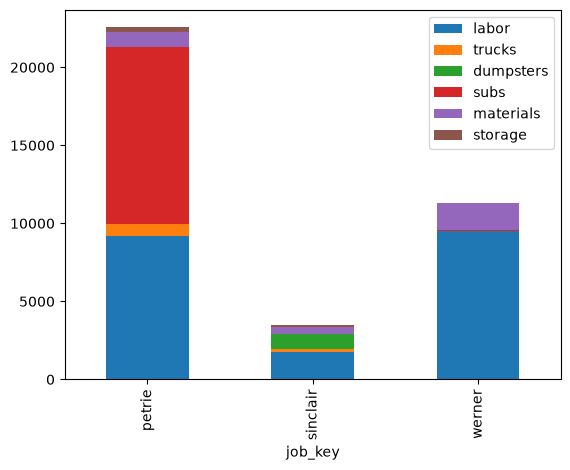

In [10]:
job_costs[cost_cols].plot.bar(stacked=True)

In [11]:
live  = pull("select id as job_id, job_number, service_type, status from jobs where deleted_at is null")
labor = pull("select job_id, hours_worked from daily_labor where job_id is not null")
sched = pull("select job_id, truck_count from job_schedule")
dump  = pull("select job_id, qty from job_billing_lines where line_key = 'dumpsters'")

for d, c in [(labor, "hours_worked"), (sched, "truck_count"), (dump, "qty")]:
    d[c] = pd.to_numeric(d[c])

live_costs = live.set_index("job_id")
live_costs["hours"]      = labor.groupby("job_id")["hours_worked"].sum()
live_costs["truck_days"] = sched.groupby("job_id")["truck_count"].sum()
live_costs["dumpsters"]  = dump.groupby("job_id")["qty"].sum()
live_costs = live_costs.fillna({"hours": 0, "truck_days": 0, "dumpsters": 0})

live_costs["labor_cost"]  = (live_costs["hours"] * labor_rate).round(2)
live_costs["truck_cost"]  = (live_costs["truck_days"] * truck_day).round(2)
live_costs["dump_cost"]   = (live_costs["dumpsters"] * dump_each).round(2)
live_costs["total_cost"]  = live_costs[["labor_cost", "truck_cost", "dump_cost"]].sum(axis=1)
live_costs.sort_values("total_cost", ascending=False)

,job_number,service_type,status,hours,truck_days,dumpsters,labor_cost,truck_cost,dump_cost,total_cost
job_id,,,,,,,,,,
c0000003-0000-0000-0000-000000000003,None,water,invoiced,223.15,3.00,0.00,"4,686.15",282.81,0.00,"4,968.96"
de547a4f-d799-410d-897c-2b72f4e15a1c,None,cleaning,scheduled,184.38,0.00,0.00,"3,871.98",0.00,0.00,"3,871.98"
7824bed8-1aa5-4af7-aaa4-091d542669af,None,fire,in_progress,83.96,2.00,2.00,"1,763.16",188.54,963.24,"2,914.94"
c0000003-0000-0000-0000-000000000036,None,fire,on_hold,105.10,0.00,1.00,"2,207.10",0.00,481.62,"2,688.72"
3d2f4f96-f79a-4504-a282-c7e6da0744dc,None,fire,scheduled,113.83,1.00,0.00,"2,390.43",94.27,0.00,"2,484.70"
...,...,...,...,...,...,...,...,...,...,...
c0000003-0000-0000-0000-000000000005,None,water,on_hold,0.00,0.00,0.00,0.00,0.00,0.00,0.00
c0000003-0000-0000-0000-000000000020,None,water,on_hold,0.00,0.00,0.00,0.00,0.00,0.00,0.00
c0000003-0000-0000-0000-000000000033,None,fire,on_hold,0.00,0.00,0.00,0.00,0.00,0.00,0.00


## Checking accuracy of Data

In [12]:
labor = pull("""select id, job_id, staff_id, work_date, stage, hours_worked,
                       clock_in, clock_out, created_at from daily_labor""")
labor["hours_worked"] = pd.to_numeric(labor["hours_worked"])
clock_hours = (labor["clock_out"] - labor["clock_in"]).dt.total_seconds() / 3600

run_checks(labor, {
    "no hours":                        labor["hours_worked"].isna(),
    "no job":                          labor["job_id"].isna(),
    "no stage":                        labor["stage"].isna(),
    "hours <= 0":                      labor["hours_worked"] <= 0,
    "hours over 14":                   labor["hours_worked"] > 14,
    "clock-out before clock-in":       clock_hours < 0,
    "hours differ from clock by >0.5": (labor["hours_worked"] - clock_hours).abs() > 0.5,
    "duplicate staff/day/job/stage":   labor.duplicated(["staff_id", "work_date", "job_id", "stage"], keep=False),
})

,rows_flagged,of_total,pct
no hours,137,488,28.10
no job,85,488,17.40
duplicate staff/day/job/stage,53,488,10.90
hours <= 0,5,488,1.00
no stage,3,488,0.60
hours over 14,2,488,0.40
clock-out before clock-in,0,488,0.00
hours differ from clock by >0.5,0,488,0.00
